
This Python notebook run the basic analysis used for the TSP manuscript, it use the data formated and combined
It saves a .csv directly usable for GLMM R script

__author__ = "C.Doussot"
__date__ =  18-February-2025

# Performance  _ Fig 4 A&B

Trajectory error, TSP success, and the combined manuscript figure. Requires the existing fitted-value CSVs produced by R. 


In [1]:
# Data handling
import os
import re
import csv
import warnings
import itertools as it

import numpy as np
import pandas as pd
from tqdm import tqdm

# Plotting
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib import cm
from matplotlib.colors import Normalize
from matplotlib.patches import FancyArrowPatch

# Networks and statistical tests
import networkx as nx
from scipy.stats import binomtest, chi2_contingency, chisquare
import statsmodels.stats.multitest as stm

# Functions stored in a1_helpers.py
from a1_helpers import (
    get_time_taken_sec,
    extract_strategies,
    get_percentages,
    parse_values,
    directed_to_undirected_with_summed_weights,
    graph_primer,
    create_dic,
    percentage_scaler,
    get_transition_df,
    Euclidean_Dist,
)

# Progress bars for pandas
tqdm.pandas()

# Hide deprecation warnings
warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=DeprecationWarning)

In [2]:
from pathlib import Path

# Run with the notebook's Analysis folder as the working directory.
assert Path('a1_helpers.py').is_file(), 'Set the working directory to the Analysis folder.'
fig_folder = '../Figure_paper/'
Path(fig_folder).mkdir(parents=True, exist_ok=True)
colors = ['#0033ff', '#ff4ff1']

In [3]:
sequence_df = pd.read_csv('../Combined_data/seq_df_2025.csv', index_col=0)
sequence_df['game'] = sequence_df['experiment'].str[-1]

In [4]:
# Keep EVERY trial; repeated node records within each trial become one row.
toplot = sequence_df.groupby(
    ['ppid', 'cond', 'scale', 'trial_num']
).first().reset_index()

# Error trajectory to optimal :

In [5]:
# Load the saved data from CSV glmm 
data = pd.read_csv('../Combined_data/data_with_fitted_values_and_sd.csv',index_col = 0)

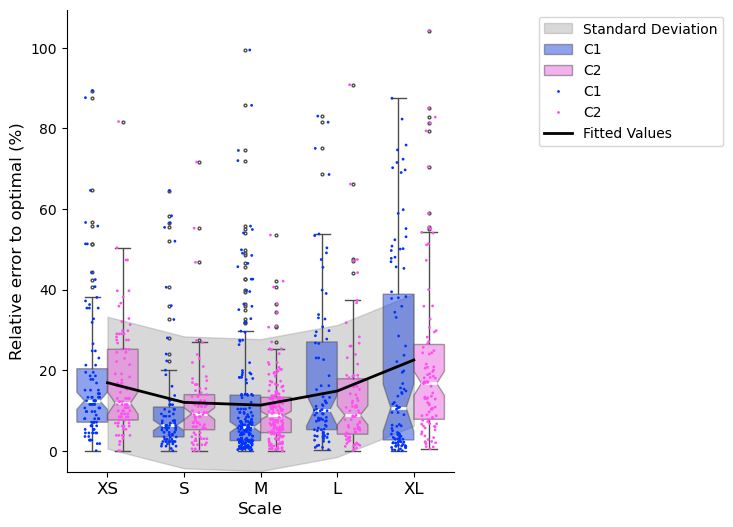

In [6]:
data= data.sort_values(by='num_scale')
# Create a figure and axis for plotting
fig, ax = plt.subplots(1, 1, figsize=(5, 6))

# Define your column names and color palette
x = 'num_scale'  # Make sure 'num_scale' is in your DataFrame
y = 'response'   # Ensure 'response' is in your DataFrame
colors = ['#0033ff','#ff4ff1']



# Add the shaded region for the standard deviation (using Matplotlib)
ax.fill_between(data['num_scale']-1, 
                data['fitted_values'] - data['sd_residuals'], 
                data['fitted_values'] + data['sd_residuals'], 
                color='gray', alpha=0.3, label="Standard Deviation")
# Plot the boxplot with Seaborn
sns.boxplot(ax=ax, data=data, x=x, y=y, hue='cond', palette=colors, notch=True, 
            boxprops={'alpha': 0.5}, medianprops={"color": "w", "linewidth": 2}, flierprops={"marker": "o", "markersize": 2})

# Plot the jittered data points (strip plot)
sns.stripplot(ax=ax, data=data, x=x, y=y, hue='cond', palette=colors, dodge=True, 
              jitter=0.2, size=2)

# Add the fitted values as a line plot (using Matplotlib)
ax.plot(data['num_scale']-1, data['fitted_values'], label='Fitted Values', color='black', linewidth=2,zorder = 100)


# Remove the top and left spines (for a cleaner look)
sns.despine(bottom=False, left=False)



# Customize the plot labels and title
ax.set_xlabel('Scale',fontsize= 12)
ax.set_ylabel('Relative error to optimal (%)',fontsize= 12)
#ax.set_title('Fitted Values with Standard Deviation')

# Add the legend outside the plot for better readability
ax.legend(bbox_to_anchor=(1.2, 1))

# Add a grid to the plot for better readability
ax.grid(False)
plt.xticks([0,1, 2,3,4], ['XS', 'S', 'M','L','XL'],fontsize= 12)
#plt.savefig(fig_folder+'Fig1_error_traj_original.png')
#plt.savefig(fig_folder+'Fig1_error_traj_original.svg')
# Show the plot
plt.show()

# Probability of correct TSP

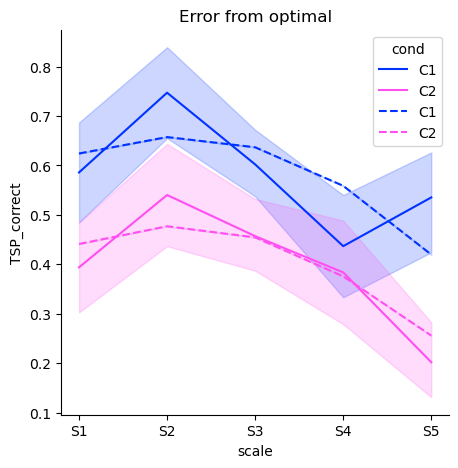

In [7]:
# Convert 'scale' to a categorical variable with the desired order
# Load the saved data from CSV

data = pd.read_csv('../Combined_data/dataTSP_with_fitted_values_and_sd.csv',index_col = 0)
data= data.sort_values(by='num_scale')
order = ['S1', 'S2', 'S3', 'S4', 'S5']

toplot['scale'] = pd.Categorical(toplot['scale'], categories = order, ordered=True)
x ="scale"
y = "TSP_correct"
fig,axes=plt.subplots(1,1,figsize=(5, 5))

hue = "cond"
sns.lineplot(ax=axes,data=toplot, x=x, y=y,hue=hue,palette = colors)

np.random.seed(42)
jitter_strength = 0.1

y_numeric = toplot['TSP_correct']
toplot['TSP_noise'] =  y_numeric + np.random.uniform(-jitter_strength, jitter_strength, size=len(y_numeric))
#sns.stripplot(ax=axes,data=toplot, x=x, y='TSP_noise', hue=hue,palette = colors,dodge=True,jitter = 0.4,size = 5,alpha = 0.5)
sns.lineplot(ax=axes,data=data, x="scale", y='fitted_values_corrected', hue=hue,palette = colors,linestyle = '--')
sns.despine(bottom = False, left = False)
axes.set_title('Error from optimal')
#plt.savefig(fig_folder+'Fig2_TSP_proba_original_fit.png')
#plt.savefig(fig_folder+'Fig2_TSP_proba_original_fit.svg')
plt.show()

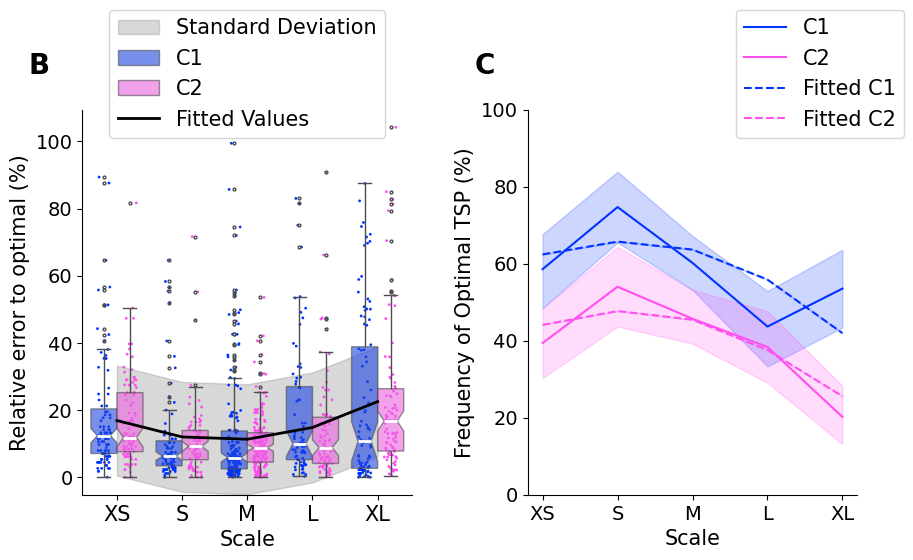

In [8]:
data = pd.read_csv('../Combined_data/data_with_fitted_values_and_sd.csv',index_col = 0)
data= data.sort_values(by='num_scale')
order = ['S1', 'S2', 'S3', 'S4', 'S5']

data['scale'] = pd.Categorical(data['scale'], categories = order, ordered=True)

# Create a figure and axis for plotting
fig, axs = plt.subplots(1, 2,figsize=(10,5))
ax = axs[0]

# Define your column names and color palette
x = 'num_scale'  # Make sure 'num_scale' is in your DataFrame
y = 'response'   # Ensure 'response' is in your DataFrame
colors = ['#0033ff','#ff4ff1']



# Add the shaded region for the standard deviation (using Matplotlib)
ax.fill_between(data['num_scale']-1, 
                data['fitted_values'] - data['sd_residuals'], 
                data['fitted_values'] + data['sd_residuals'], 
                color='gray', alpha=0.3, label="Standard Deviation",zorder=-1)

# Plot the boxplot with Seaborn
sns.boxplot(ax=ax, data=data, x=x, y=y, hue='cond', palette=colors, notch=True, 
            boxprops={'alpha': 0.6}, medianprops={"color": "w", "linewidth": 2}, flierprops={"marker": "o", "markersize": 2},zorder=100)

# Plot the jittered data points (strip plot)
sns.stripplot(ax=ax, data=data, x=x, y=y, hue='cond', palette=colors, dodge=True, 
              jitter=0.2, size=2,legend = False)

# Add the fitted values as a line plot (using Matplotlib)
ax.plot(data['num_scale']-1, data['fitted_values'], label='Fitted Values', color='black', linewidth=2,zorder = 1000)


# Remove the top and left spines (for a cleaner look)
sns.despine(bottom=False, left=False)



# Customize the plot labels and title
ax.set_xlabel('Scale',fontsize= 15)
ax.set_ylabel('Relative error to optimal (%)',fontsize= 15)
#ax.set_title('Fitted Values with Standard Deviation')

# Add the legend outside the plot for better readability

ax.legend(bbox_to_anchor=(0.5, 0.9),fontsize= 15)
# Add a grid to the plot for better readability
ax.grid(False)
ax.tick_params(axis='both', which='major', labelsize=14)
ax.tick_params(axis='both', which='minor', labelsize=10)
ax.set_xticks([0,1, 2,3,4], ['XS', 'S', 'M','L','XL'],fontsize= 15)
ax.text(-0.1, 1.15, 'B', transform=ax.transAxes,
    fontsize=20, fontweight='bold', va='top', ha='right')


# Convert 'scale' to a categorical variable with the desired order
# Load the saved data from CSV

data = pd.read_csv('../Combined_data/dataTSP_with_fitted_values_and_sd.csv',index_col = 0)
data= data.sort_values(by='num_scale')
ax = axs[1]

order = ['S1', 'S2', 'S3', 'S4', 'S5']

toplot['scale'] = pd.Categorical(toplot['scale'], categories = order, ordered=True)

x ="scale"
y = "TSP_correct"

hue = "cond"
toplot['TSP_percentage']= toplot['TSP_correct'] *100

sns.lineplot(data = toplot, x="scale", y= "TSP_percentage",hue=hue,palette = colors, ax =ax)

data_fit = data.copy()
data_fit['cond'] = data_fit['cond'].map({'C1': "Fitted C1", 'C2': "Fitted C2"})

data_fit['TSP_fit_percentage']  = data_fit['fitted_values_corrected'] *100
sns.lineplot(data = data_fit, x="scale", y='TSP_fit_percentage', hue=hue,palette = colors,linestyle = '--', ax=ax)



sns.despine(bottom = False, left = False)
ax.set_ylabel('Frequency of Optimal TSP (%)',fontsize= 15)
ax.set_xlabel('Scale',fontsize= 15)
ax.set_xticks([0,1, 2,3,4], ['XS', 'S', 'M','L','XL'],fontsize= 15)

ax.legend(bbox_to_anchor=(0.6, 0.9),fontsize= 15)

ax.set_ylim(0,100)
ax.text(-0.1, 1.15, 'C', transform=ax.transAxes,
    fontsize=20, fontweight='bold', va='top', ha='right')
ax.tick_params(axis='both', which='major', labelsize=14)
ax.tick_params(axis='both', which='minor', labelsize=10)

plt.subplots_adjust( wspace=0.35)
#plt.savefig(fig_folder+'Fig3BC_ResultsExp2.png',dpi = 330,bbox_inches='tight')
#plt.savefig(fig_folder+'Fig3BC_ResultsExp2.svg',dpi = 330,bbox_inches='tight')
plt.show()